In [81]:
import pandas as pd
import numpy as np
import seaborn as sns
path = r"/Users/bittu/Downloads/sheet.xlsx"
df = pd.read_excel(path)
print(df)

   S.No   A   B   C   D   E   F  Length
0     1   2   1   5   3   4   6      73
1     2   4   3  10   6   8  12      47
2     3   6   5  15   9  12  18      34
3     4   8   7  20  12  16  24      54
4     5  10   9  25  15  20  39      89
5     6  12  11  30  18  24  36      48
6     7  14  13  35  32  28  42      64
7     8  16  15  40  24  32  48      56
8     9  18  17  43  34  36  54      32
9    10  20  19  22  30  40  23      48


In [71]:
bins = np.linspace(min(df["Length"]),max(df["Length"]),4)

In [72]:
group_names = ["low","Medium","high"]

In [73]:
df["Length-binned"] = pd.cut(df["Length"],bins,labels = group_names,include_lowest = True)

In [74]:
df.head(10)

,S.No,A,B,C,D,E,F,Length,Length-binned
0,1,2,1,5,3,4,6,73,high
1,2,4,3,10,6,8,12,47,Medium
2,3,6,5,15,9,12,18,34,low
3,4,8,7,20,12,16,24,54,Medium
4,5,10,9,25,15,20,39,89,high
5,6,12,11,30,18,24,36,23,low
6,7,14,13,35,32,28,42,64,Medium
7,8,16,15,40,24,32,48,56,Medium
8,9,18,17,43,34,36,54,32,low
9,10,20,19,22,30,40,23,48,Medium


In [75]:
# Catgroical to Numeric
# pd.get_dummies(df["Length"])
pd.get_dummies(df["Length"],dtype = int)

,23,32,34,47,48,54,56,64,73,89
0,0,0,0,0,0,0,0,0,1,0
1,0,0,0,1,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,1
5,1,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,1,0,0
7,0,0,0,0,0,0,1,0,0,0
8,0,1,0,0,0,0,0,0,0,0
9,0,0,0,0,1,0,0,0,0,0


In [76]:
df.describe()

,S.No,A,B,C,D,E,F,Length
count,10.00000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,5.50000,11.000000,10.000000,24.500000,18.300000,22.000000,30.200000,52.000000
std,3.02765,6.055301,6.055301,12.607317,11.185804,12.110601,15.949922,19.944367
min,1.00000,2.000000,1.000000,5.000000,3.000000,4.000000,6.000000,23.000000
25%,3.25000,6.500000,5.500000,16.250000,9.750000,13.000000,19.250000,37.250000
50%,5.50000,11.000000,10.000000,23.500000,16.500000,22.000000,30.000000,51.000000
75%,7.75000,15.500000,14.500000,33.750000,28.500000,31.000000,41.250000,62.000000
max,10.00000,20.000000,19.000000,43.000000,34.000000,40.000000,54.000000,89.000000


In [77]:
df.head()

,S.No,A,B,C,D,E,F,Length,Length-binned
0,1,2,1,5,3,4,6,73,high
1,2,4,3,10,6,8,12,47,Medium
2,3,6,5,15,9,12,18,34,low
3,4,8,7,20,12,16,24,54,Medium
4,5,10,9,25,15,20,39,89,high


In [78]:
index= pd.Index(df["Length"])

In [79]:
index.value_counts()

Length
73    1
47    1
34    1
54    1
89    1
23    1
64    1
56    1
32    1
48    1
Name: count, dtype: int64

<Axes: xlabel='Length', ylabel='E'>

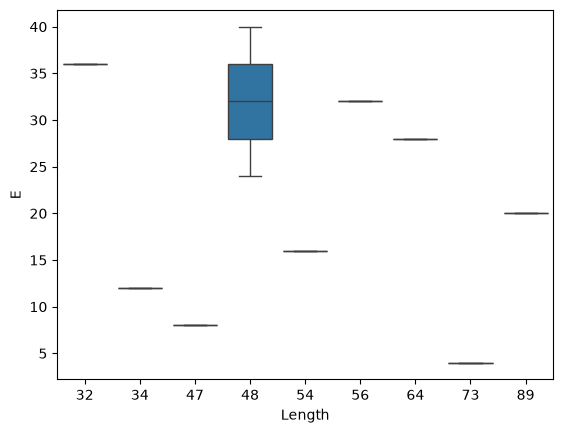

In [82]:
# Box Plot
sns.boxplot(x="Length" , y="E" ,data=df  )


Text(0, 0.5, 'Width')

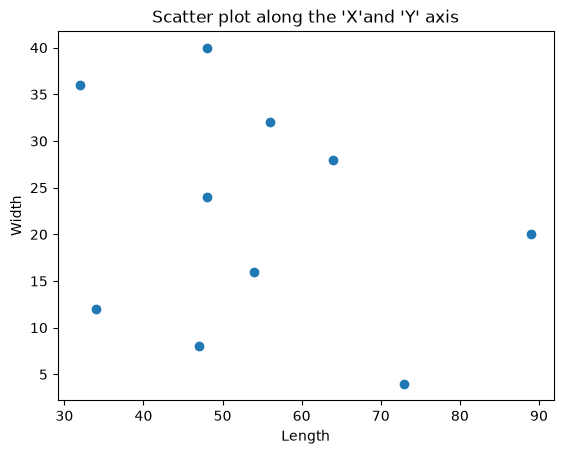

In [86]:
# SCATTERPLOT
import matplotlib.pyplot as plt
x= df["Length"]
y = df["E"] 
plt.scatter(x,y)
plt.title("Scatter plot along the 'X'and 'Y' axis")
plt.xlabel("Length")
plt.ylabel("Width")

In [90]:
grp = df.groupby(["B","A"])
grp.aggregate(np.sum)

,,S.No,C,D,E,F,Length
B,A,,,,,,
1,2,1,5,3,4,6,73
3,4,2,10,6,8,12,47
5,6,3,15,9,12,18,34
7,8,4,20,12,16,24,54
9,10,5,25,15,20,39,89
11,12,6,30,18,24,36,48
13,14,7,35,32,28,42,64
15,16,8,40,24,32,48,56
17,18,9,43,34,36,54,32


In [93]:
grp = df.groupby(["S.No","A","B"],as_index = False)
grp.aggregate(np.sum)

,S.No,A,B,C,D,E,F,Length
0,1,2,1,5,3,4,6,73
1,2,4,3,10,6,8,12,47
2,3,6,5,15,9,12,18,34
3,4,8,7,20,12,16,24,54
4,5,10,9,25,15,20,39,89
5,6,12,11,30,18,24,36,48
6,7,14,13,35,32,28,42,64
7,8,16,15,40,24,32,48,56
8,9,18,17,43,34,36,54,32
9,10,20,19,22,30,40,23,48


In [94]:
grp.size()

,S.No,A,B,size
0,1,2,1,1
1,2,4,3,1
2,3,6,5,1
3,4,8,7,1
4,5,10,9,1
5,6,12,11,1
6,7,14,13,1
7,8,16,15,1
8,9,18,17,1
9,10,20,19,1


In [95]:
grp.count()

,S.No,A,B,C,D,E,F,Length
0,1,2,1,1,1,1,1,1
1,2,4,3,1,1,1,1,1
2,3,6,5,1,1,1,1,1
3,4,8,7,1,1,1,1,1
4,5,10,9,1,1,1,1,1
5,6,12,11,1,1,1,1,1
6,7,14,13,1,1,1,1,1
7,8,16,15,1,1,1,1,1
8,9,18,17,1,1,1,1,1
9,10,20,19,1,1,1,1,1


In [98]:
I = [["Shivam",1],["Shivam",2],["Bittu",1],["Bittu",2],["Piyush",1],["Piyush",2]]
df_2 = pd.DataFrame(I,columns = ["A","B"])
print(df_2)

        A  B
0  Shivam  1
1  Shivam  2
2   Bittu  1
3   Bittu  2
4  Piyush  1
5  Piyush  2


In [108]:
df_2.groupby("A")["B"].nunique()

A
Bittu     2
Piyush    2
Shivam    2
Name: B, dtype: int64

In [109]:
df_2.groupby("A")["A"].nunique()

A
Bittu     1
Piyush    1
Shivam    1
Name: A, dtype: int64

In [18]:
import pandas as pd
df_3 = pd.DataFrame({
'S.No':[1,2,3,4,5],
'A':['Apple','According','After','Artificial','Addition'],
'B':['Book','Bat','Bad','Baby','Bitch'],
'C':['Cook','Cold','Coffe','Cheaks','Chekan'],
'D':['Dog','Deep','Dady','Dummy','Dick'],
'E':['Eat','Economics','Ego','Earphone','Engineer']})
print(df_3)

   S.No           A      B       C      D          E
0     1       Apple   Book    Cook    Dog        Eat
1     2   According    Bat    Cold   Deep  Economics
2     3       After    Bad   Coffe   Dady        Ego
3     4  Artificial   Baby  Cheaks  Dummy   Earphone
4     5    Addition  Bitch  Chekan   Dick   Engineer


In [21]:
df_3.pivot(index = 'A',columns = 'B',values = 'C')

B,Baby,Bad,Bat,Bitch,Book
A,,,,,
According,NaN,NaN,Cold,NaN,NaN
Addition,NaN,NaN,NaN,Chekan,NaN
After,NaN,Coffe,NaN,NaN,NaN
Apple,NaN,NaN,NaN,NaN,Cook
Artificial,Cheaks,NaN,NaN,NaN,NaN


In [24]:
df_3.pivot(index = 'A',columns ='B')['C']

B,Baby,Bad,Bat,Bitch,Book
A,,,,,
According,NaN,NaN,Cold,NaN,NaN
Addition,NaN,NaN,NaN,Chekan,NaN
After,NaN,Coffe,NaN,NaN,NaN
Apple,NaN,NaN,NaN,NaN,Cook
Artificial,Cheaks,NaN,NaN,NaN,NaN


In [23]:
df_3.pivot(index = 'S.No',columns ='A')['B']

A,According,Addition,After,Apple,Artificial
S.No,,,,,
1,NaN,NaN,NaN,Book,NaN
2,Bat,NaN,NaN,NaN,NaN
3,NaN,NaN,Bad,NaN,NaN
4,NaN,NaN,NaN,NaN,Baby
5,NaN,Bitch,NaN,NaN,NaN


In [31]:
df_3.pivot(index = 'S.No',columns ='A')[['C','B']]

C                                          B                 \
A    According Addition  After Apple Artificial According Addition After   
S.No                                                                       
1          NaN      NaN    NaN  Cook        NaN       NaN      NaN   NaN   
2         Cold      NaN    NaN   NaN        NaN       Bat      NaN   NaN   
3          NaN      NaN  Coffe   NaN        NaN       NaN      NaN   Bad   
4          NaN      NaN    NaN   NaN     Cheaks       NaN      NaN   NaN   
5          NaN   Chekan    NaN   NaN        NaN       NaN    Bitch   NaN   

                       
A    Apple Artificial  
S.No                   
1     Book        NaN  
2      NaN        NaN  
3      NaN        NaN  
4      NaN       Baby  
5      NaN        NaN

In [32]:
df_3.pivot(index = 'S.No',columns = 'A',values = ['B','C'])

B                                         C                  \
A    According Addition After Apple Artificial According Addition  After   
S.No                                                                       
1          NaN      NaN   NaN  Book        NaN       NaN      NaN    NaN   
2          Bat      NaN   NaN   NaN        NaN      Cold      NaN    NaN   
3          NaN      NaN   Bad   NaN        NaN       NaN      NaN  Coffe   
4          NaN      NaN   NaN   NaN       Baby       NaN      NaN    NaN   
5          NaN    Bitch   NaN   NaN        NaN       NaN   Chekan    NaN   

                       
A    Apple Artificial  
S.No                   
1     Cook        NaN  
2      NaN        NaN  
3      NaN        NaN  
4      NaN     Cheaks  
5      NaN        NaN

In [38]:
import numpy as np
np.random.seed(0)
import seaborn as sns

uniform_data = np.random.rand(5,6) 
print(uniform_data)

[[0.5488135  0.71518937 0.60276338 0.54488318 0.4236548  0.64589411]
 [0.43758721 0.891773   0.96366276 0.38344152 0.79172504 0.52889492]
 [0.56804456 0.92559664 0.07103606 0.0871293  0.0202184  0.83261985]
 [0.77815675 0.87001215 0.97861834 0.79915856 0.46147936 0.78052918]
 [0.11827443 0.63992102 0.14335329 0.94466892 0.52184832 0.41466194]]


In [38]:
import numpy as np
np.random.seed(0)
import seaborn as sns

uniform_data = np.random.rand(5,6) 
print(uniform_data)

[[0.5488135  0.71518937 0.60276338 0.54488318 0.4236548  0.64589411]
 [0.43758721 0.891773   0.96366276 0.38344152 0.79172504 0.52889492]
 [0.56804456 0.92559664 0.07103606 0.0871293  0.0202184  0.83261985]
 [0.77815675 0.87001215 0.97861834 0.79915856 0.46147936 0.78052918]
 [0.11827443 0.63992102 0.14335329 0.94466892 0.52184832 0.41466194]]


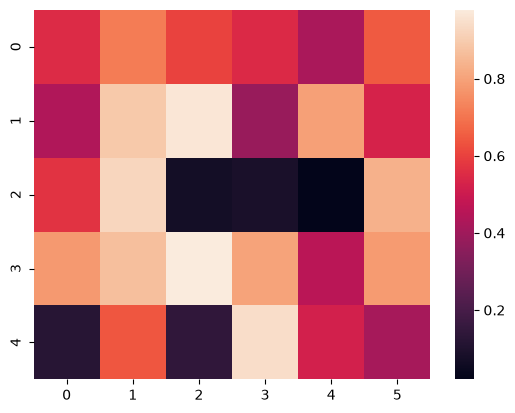

In [39]:
heat_map = sns.heatmap(uniform_data)

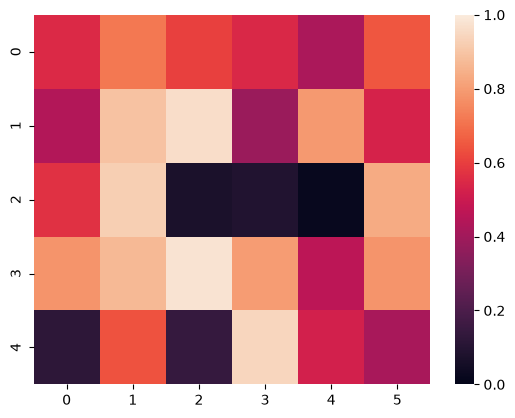

In [40]:
heat_map01 = sns.heatmap(uniform_data,vmin = 0,vmax = 1)

In [43]:
normal_data = np.random.randn(6,6)
print(normal_data)

[[-0.63432209 -0.36274117 -0.67246045 -0.35955316 -0.81314628 -1.7262826 ]
 [ 0.17742614 -0.40178094 -1.63019835  0.46278226 -0.90729836  0.0519454 ]
 [ 0.72909056  0.12898291  1.13940068 -1.23482582  0.40234164 -0.68481009]
 [-0.87079715 -0.57884966 -0.31155253  0.05616534 -1.16514984  0.90082649]
 [ 0.46566244 -1.53624369  1.48825219  1.89588918  1.17877957 -0.17992484]
 [-1.07075262  1.05445173 -0.40317695  1.22244507  0.20827498  0.97663904]]


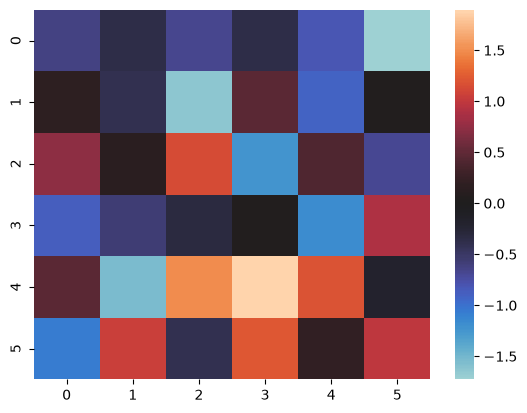

In [46]:
heat_map02 = sns.heatmap(normal_data,center  =0)

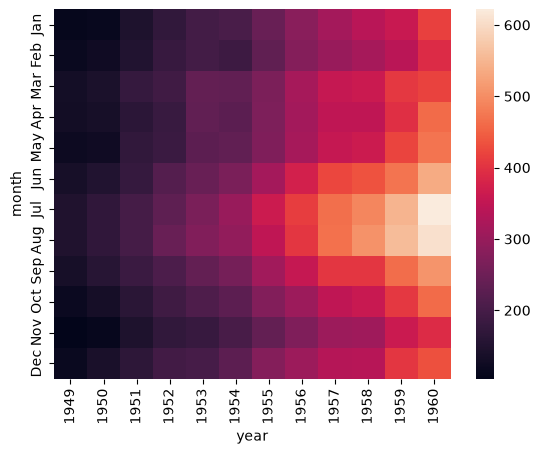

In [48]:
flights = sns.load_dataset('flights')
flights = flights.pivot(
    index="month",
    columns="year",
    values="passengers"
)
heat_map03 = sns.heatmap(flights)

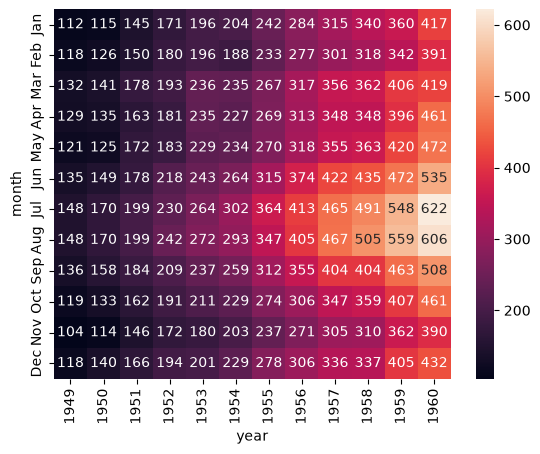

In [49]:
heat_map03 = sns.heatmap(flights,annot = True,fmt = "d")

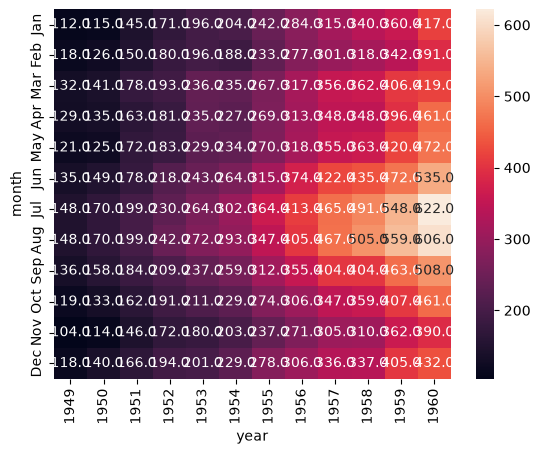

In [51]:
heat_map04 = sns.heatmap(flights,annot = True,fmt = ".1f")

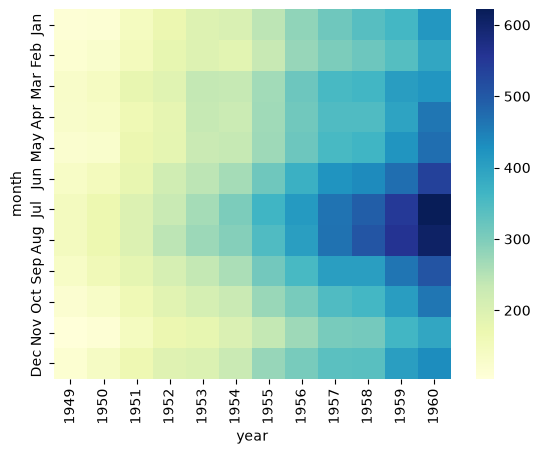

In [54]:
heat_map05 = sns.heatmap(flights,cmap = "YlGnBu")

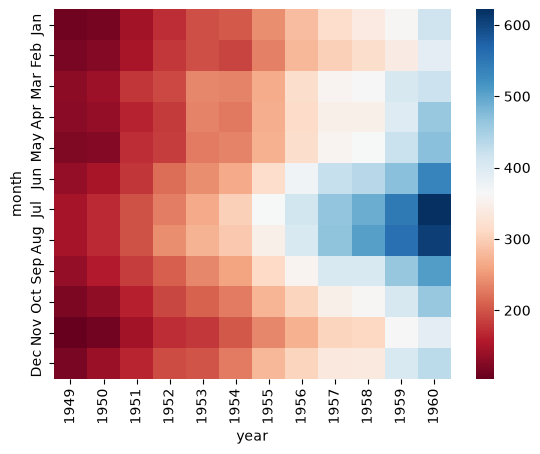

In [55]:
heat_map06 = sns.heatmap(flights,cmap = "RdBu")

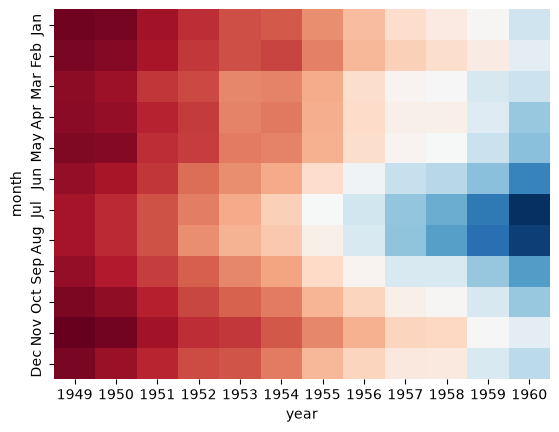

In [58]:
 heat_map06 = sns.heatmap(flights,cmap = "RdBu",cbar = False)

<Axes: xlabel='passengers', ylabel='year'>

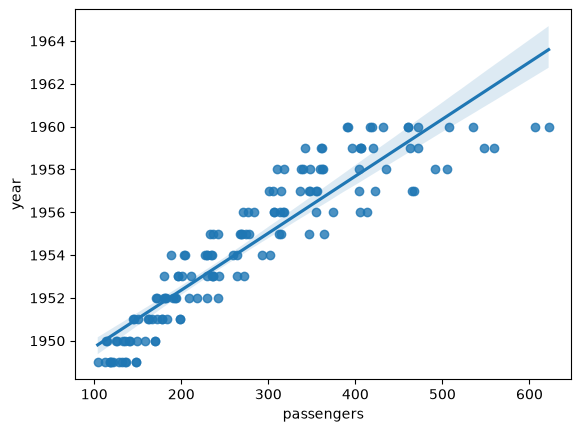

In [61]:
flights = sns.load_dataset("flights")
sns.regplot(x ="passengers",y ="year", data = flights) 

In [62]:
from scipy import stats
flight = sns.load_dataset("flights")
print(flights)

     year month  passengers
0    1949   Jan         112
1    1949   Feb         118
2    1949   Mar         132
3    1949   Apr         129
4    1949   May         121
..    ...   ...         ...
139  1960   Aug         606
140  1960   Sep         508
141  1960   Oct         461
142  1960   Nov         390
143  1960   Dec         432

[144 rows x 3 columns]


In [63]:
pearson_correlation = stats.pearsonr(flights['year'],flights['passengers'])
print(pearson_correlation)

PearsonRResult(statistic=np.float64(0.9218238352924201), pvalue=np.float64(2.58104255191102e-60))
